# Trabajo Práctico Integrador - Introducción al Análisis de datos
## Entrega 4: Análisis exploratorio de Datos.


## Caso: análisis y predicción de cancelaciones en reservas hoteleras.

## Lenguaje utilizado: Python y SQL


## 1. Datos de identificación

- **Apellido y nombre:** Rodriguez Joaquin - Pichulman Miguel
- **Comisión:** 12
- **Dataset asignado:** L
- **Entrega:** 3
- **Fecha:** 09 / 10 / 2026

# 2. Preparación del dataset


In [10]:
#@title Preparación automática del entorno (ejecutar sin modificar)
import duckdb
import pandas as pd

# Carga de datos
url = "https://raw.githubusercontent.com/MiguelPichulman/cuartoCuatrimestre/main/analisisDatos/integrador/master/dataset_limpio/hotel_booking_LyT.csv"
reservas = pd.read_csv(url)

con = duckdb.connect(":memory:")
con.register("reservas_df", reservas)
con.execute("CREATE OR REPLACE TABLE reservas AS SELECT * FROM reservas_df")

print(f"Entorno preparado: {len(reservas):,} registros disponibles en la tabla 'reservas'.")

Entorno preparado: 24,927 registros disponibles en la tabla 'reservas'.


### 1. Unidad de análisis del dataset y representación de cada fila
Unidad de análisis: Cada reserva de hotel individual gestionada y registrada por los establecimientos (incluyendo tanto hoteles urbanos como de playa/resorts).

Representación de cada fila: Cada registro de la tabla corresponde a una reserva de hotel específica conteniendo información detallada sobre el tiempo de anticipación, características de la estadía, tipo de cliente, tarifas y el estado final de la reserva (si fue cancelada o concretada).

### 2. Significado y valores de la variable is_canceled
Definición: La variable is_canceled indica si la reserva fue cancelada o no por el cliente.

Valores posibles:

- 0: La reserva no fue cancelada (el huésped se hospedó o completó el proceso).

- 1: La reserva fue cancelada por el cliente.

### 3. Revisión de la estructura

In [11]:
# A. Cantidad de filas y columnas
print("--- DIMENSIONES DE LA TABLA ---")
display(con.sql("""
    SELECT
        COUNT() AS total_filas
    FROM reservas
"""))

# B. Tipos de datos y estructura de columnas
print("--- TIPOS DE DATOS Y COLUMNAS ---")
display(con.sql("DESCRIBE reservas"))

# C. Primeras observaciones
print("--- PRIMERAS OBSERVACIONES ---")
display(con.sql("SELECT * FROM reservas LIMIT 3").df())

--- DIMENSIONES DE LA TABLA ---


┌─────────────┐
│ total_filas │
│    int64    │
├─────────────┤
│       24927 │
└─────────────┘

--- TIPOS DE DATOS Y COLUMNAS ---


┌────────────────────────────────┬─────────────┬─────────┬─────────┬─────────┬─────────┐
│          column_name           │ column_type │  null   │   key   │ default │  extra  │
│            varchar             │   varchar   │ varchar │ varchar │ varchar │ varchar │
├────────────────────────────────┼─────────────┼─────────┼─────────┼─────────┼─────────┤
│ hotel                          │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ is_canceled                    │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ lead_time                      │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ arrival_date                   │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ stays_in_weekend_nights        │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ stays_in_week_nights           │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ adults                         │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ children           

--- PRIMERAS OBSERVACIONES ---


,hotel,is_canceled,lead_time,arrival_date,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,...,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests
0,City Hotel,1,302,2024-05-05,0,2,2,0.0,0,BB,...,0,A,A,0,Non Refund,0,Transient,62.0,0,0
1,City Hotel,1,65,2023-09-05,1,1,2,0.0,0,BB,...,0,A,A,0,Non Refund,0,Transient,62.0,0,0
2,City Hotel,0,32,2025-05-30,0,2,2,0.0,0,SC,...,0,A,A,0,No Deposit,0,Transient,160.0,0,2


### 4. Selección de variables relevantes
- is_canceled (Cualitativa binaria): Estado de cancelación de la reserva.

- lead_time (Cuantitativa continua/discreta): Días de anticipación transcurridos entre la fecha de reserva y la fecha de llegada.


- adr (Cuantitativa continua): Tarifa diaria promedio (Average Daily Rate), calculada dividiendo la suma de todas las transacciones de alojamiento entre el total de noches de estadía.

- market_segment (Cualitativa categórica): Segmento de mercado de procedencia de la reserva.

### 5. Distribución de is_canceled (tabla de frecuencia)


--- TABLA DE FRECUENCIAS: is_canceled ---


┌─────────────┬──────────┬────────────┐
│ is_canceled │ cantidad │ porcentaje │
│    int64    │  int64   │   double   │
├─────────────┼──────────┼────────────┤
│           0 │    15766 │      63.25 │
│           1 │     9161 │      36.75 │
└─────────────┴──────────┴────────────┘

/tmp/ipykernel_886/1662806397.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_freq, x='is_canceled', y='cantidad', palette='Blues_d')


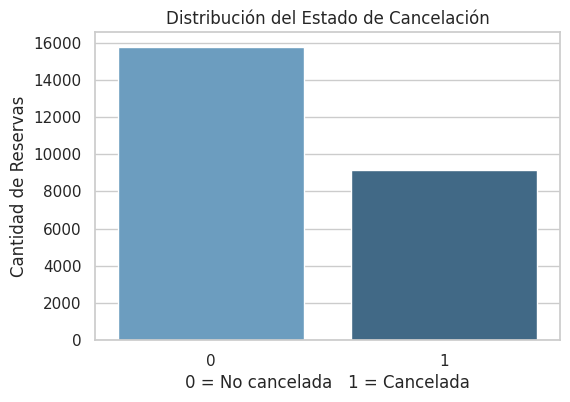

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Tabla de frecuencias mediante DuckDB
print("--- TABLA DE FRECUENCIAS: is_canceled ---")
freq_cancelada = con.sql("""
SELECT
    is_canceled,
    COUNT(*) AS cantidad,
    ROUND(COUNT(*) * 100.0 / (SELECT COUNT(*) FROM reservas), 2) AS porcentaje
FROM reservas
GROUP BY is_canceled
ORDER BY is_canceled
""")
display(freq_cancelada)

# Visualización simple
df_freq = freq_cancelada.df()
plt.figure(figsize=(6, 4))
sns.barplot(data=df_freq, x='is_canceled', y='cantidad', palette='Blues_d')
plt.title('Distribución del Estado de Cancelación')
plt.xlabel('0 = No cancelada   1 = Cancelada')
plt.ylabel('Cantidad de Reservas')
plt.show()

### 6. Resumen descriptivo para lead_time, adr y market_segment

In [13]:
# A. Resumen descriptivo para variable cuantitativa: lead_time y adr
print("--- RESUMEN ESTADÍSTICO DE VARIABLES CUANTITATIVAS ---")
display(con.sql("""
SELECT
    ROUND(AVG(lead_time), 2) AS media_lead_time,
    PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY lead_time) AS mediana_lead_time,
    ROUND(AVG(adr), 2) AS media_adr,
    PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY adr) AS mediana_adr
FROM reservas
"""))

# B. Tabla de frecuencias para variable categórica o temporal: market_segment
print("--- TABLA DE FRECUENCIAS: market_segment ---")
display(con.sql("""
SELECT
    market_segment,
    COUNT(*) AS total_reservas,
    ROUND(COUNT(*) * 100.0 / (SELECT COUNT(*) FROM reservas), 2) AS porcentaje
FROM reservas
GROUP BY market_segment
ORDER BY total_reservas DESC
"""))

--- RESUMEN ESTADÍSTICO DE VARIABLES CUANTITATIVAS ---


┌─────────────────┬───────────────────┬───────────┬─────────────┐
│ media_lead_time │ mediana_lead_time │ media_adr │ mediana_adr │
│     double      │      double       │  double   │   double    │
├─────────────────┼───────────────────┼───────────┼─────────────┤
│           104.1 │              70.0 │    102.29 │        95.0 │
└─────────────────┴───────────────────┴───────────┴─────────────┘

--- TABLA DE FRECUENCIAS: market_segment ---


┌────────────────┬────────────────┬────────────┐
│ market_segment │ total_reservas │ porcentaje │
│    varchar     │     int64      │   double   │
├────────────────┼────────────────┼────────────┤
│ Online TA      │          11860 │      47.58 │
│ Offline TA/TO  │           4984 │      19.99 │
│ Groups         │           4156 │      16.67 │
│ Direct         │           2653 │      10.64 │
│ Corporate      │           1071 │        4.3 │
│ Complementary  │            139 │       0.56 │
│ Aviation       │             64 │       0.26 │
└────────────────┴────────────────┴────────────┘

### 7. Visualizaciones

/tmp/ipykernel_886/1265755943.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=reservas, y='market_segment', order=reservas['market_segment'].value_counts().index, ax=axes[1], palette='crest')


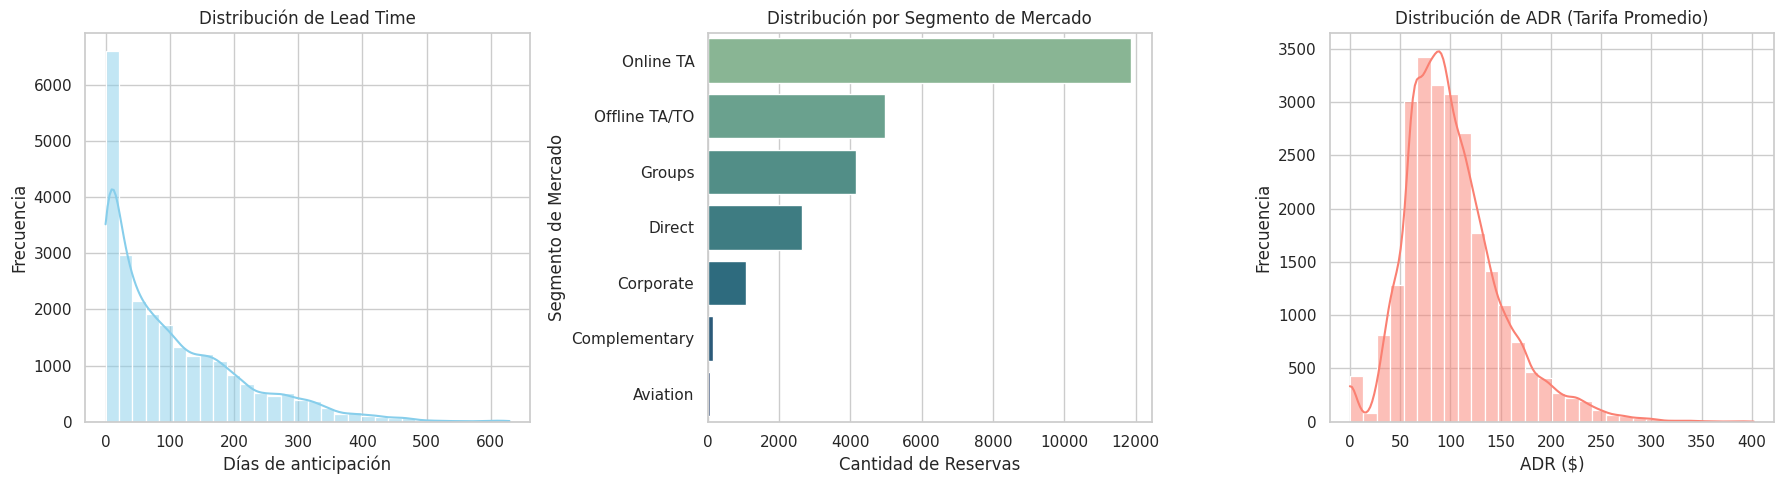

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Histograma para lead_time
sns.histplot(reservas['lead_time'], bins=30, kde=True, ax=axes[0], color='skyblue')
axes[0].set_title('Distribución de Lead Time')
axes[0].set_xlabel('Días de anticipación')
axes[0].set_ylabel('Frecuencia')

# 2. Gráfico de barras para market_segment
sns.countplot(data=reservas, y='market_segment', order=reservas['market_segment'].value_counts().index, ax=axes[1], palette='crest')
axes[1].set_title('Distribución por Segmento de Mercado')
axes[1].set_xlabel('Cantidad de Reservas')
axes[1].set_ylabel('Segmento de Mercado')

# 3. Histograma / Boxplot para adr (tarifa diaria promedio)
sns.histplot(reservas['adr'].dropna(), bins=30, kde=True, ax=axes[2], color='salmon')
axes[2].set_title('Distribución de ADR (Tarifa Promedio)')
axes[2].set_xlabel('ADR ($)')
axes[2].set_ylabel('Frecuencia')

plt.tight_layout()
plt.show()

### 8. Interpretaciones breves de los resultados
De la tabla de frecuencias de cancelaciones: Se observa que una porción considerable de las reservas del dataset finalizan en cancelación (is_canceled = 1), mientras que la mayoría se concreta de manera efectiva (is_canceled = 0).

De los estadísticos cuantitativos (lead_time y adr): El tiempo de anticipación presenta una dispersión amplia, con reservas hechas el mismo día y otras con más de un año de anticipación. La tarifa diaria promedio (adr) muestra valores centrados en rangos habituales de hotelería, aunque registra presencia de valores atípicos o extremos (tarifas negativas o muy elevadas).

De la distribución de segmentos de mercado: El segmento de agencias de viaje concentra la gran mayoría de las reservas en comparación con los canales corporativos o reservas directas.

### 9. Preguntas e hipótesis exploratorias
¿Existe una relación directa entre un mayor tiempo de anticipación (lead_time) y la probabilidad de cancelación de la reserva (is_canceled)?

¿Cómo varía el comportamiento de cancelación según el segmento de mercado de origen (market_segment)?

¿Impacta la tarifa diaria promedio (adr) en la decisión de cancelar o mantener una reserva hotelera?

### 10. Comparación mediante SQL para los grupos de reservas canceladas frente a las no canceladas en función de las variables lead_time, market_segment y adr.

In [15]:
import duckdb
import pandas as pd

# Carga de datos
url = "https://raw.githubusercontent.com/MiguelPichulman/cuartoCuatrimestre/main/analisisDatos/integrador/master/dataset_limpio/hotel_booking_LyT.csv"
reservas = pd.read_csv(url)

con = duckdb.connect(":memory:")
con.register("reservas_df", reservas)
con.execute("CREATE OR REPLACE TABLE reservas AS SELECT * FROM reservas_df")

# A. Comparación de Lead Time según estado de cancelación
print("--- 1. LEAD TIME SEGÚN CANCELACIÓN ---")
display(con.sql("""
SELECT
    is_canceled,
    COUNT(*) AS total_reservas,
    ROUND(AVG(lead_time), 2) AS lead_time_promedio,
    PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY lead_time) AS lead_time_mediana
FROM reservas
GROUP BY is_canceled
ORDER BY is_canceled
"""))

# B. Comparación de Cancelaciones por Segmento de Mercado
print("--- 2. CANCELACIONES POR SEGMENTO DE MERCADO ---")
display(con.sql("""
SELECT
    market_segment,
    COUNT(*) AS total_reservas,
    SUM(is_canceled) AS total_canceladas,
    ROUND(SUM(is_canceled) * 100.0 / COUNT(*), 2) AS tasa_cancelacion_porcentaje
FROM reservas
GROUP BY market_segment
ORDER BY tasa_cancelacion_porcentaje DESC
"""))

# C. Comparación de ADR (Tarifa Promedio) según cancelación
print("--- 3. ADR SEGÚN CANCELACIÓN ---")
display(con.sql("""
SELECT
    is_canceled,
    ROUND(AVG(adr), 2) AS adr_promedio,
    PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY adr) AS adr_mediana
FROM reservas
GROUP BY is_canceled
ORDER BY is_canceled
"""))

--- 1. LEAD TIME SEGÚN CANCELACIÓN ---


┌─────────────┬────────────────┬────────────────────┬───────────────────┐
│ is_canceled │ total_reservas │ lead_time_promedio │ lead_time_mediana │
│    int64    │     int64      │       double       │      double       │
├─────────────┼────────────────┼────────────────────┼───────────────────┤
│           0 │          15766 │              79.79 │              46.0 │
│           1 │           9161 │             145.94 │             115.0 │
└─────────────┴────────────────┴────────────────────┴───────────────────┘

--- 2. CANCELACIONES POR SEGMENTO DE MERCADO ---


┌────────────────┬────────────────┬──────────────────┬─────────────────────────────┐
│ market_segment │ total_reservas │ total_canceladas │ tasa_cancelacion_porcentaje │
│    varchar     │     int64      │      int128      │           double            │
├────────────────┼────────────────┼──────────────────┼─────────────────────────────┤
│ Groups         │           4156 │             2545 │                       61.24 │
│ Online TA      │          11860 │             4349 │                       36.67 │
│ Offline TA/TO  │           4984 │             1663 │                       33.37 │
│ Corporate      │           1071 │              197 │                       18.39 │
│ Aviation       │             64 │               10 │                       15.63 │
│ Direct         │           2653 │              386 │                       14.55 │
│ Complementary  │            139 │               11 │                        7.91 │
└────────────────┴────────────────┴──────────────────┴───────────

--- 3. ADR SEGÚN CANCELACIÓN ---


┌─────────────┬──────────────┬─────────────┐
│ is_canceled │ adr_promedio │ adr_mediana │
│    int64    │    double    │   double    │
├─────────────┼──────────────┼─────────────┤
│           0 │        100.4 │        93.0 │
│           1 │       105.55 │       96.91 │
└─────────────┴──────────────┴─────────────┘

- ## Resumen descriptivo
- Para el tiempo de anticipación (lead_time): Las reservas que terminan en cancelación presentan en promedio un lead_time significativamente más alto que las que se concretan, evidenciando que los clientes que reservan con mucha anticipación tienen mayor riesgo de cancelar.

- Para el segmento de mercado (market_segment): Existen diferencias marcadas. Segmentos masivos muestran volúmenes elevados y tasas de cancelación considerables en comparación con canales directos o corporativos.

- Para la tarifa (adr): Se observan diferencias sutiles en la tarifa diaria promedio entre las reservas canceladas y las mantenidas, requiriendo atención a valores extremos o atípicos.

- ## Visualizaciones exploratorias

/tmp/ipykernel_886/3557938898.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=reservas, x='is_canceled', y='lead_time', ax=axes[0], palette='Set2')
/tmp/ipykernel_886/3557938898.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_market, x='tasa', y='market_segment', ax=axes[1], palette='Blues_r')
/tmp/ipykernel_886/3557938898.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=reservas, x='is_canceled', y='adr', ax=axes[2], palette='Pastel1')


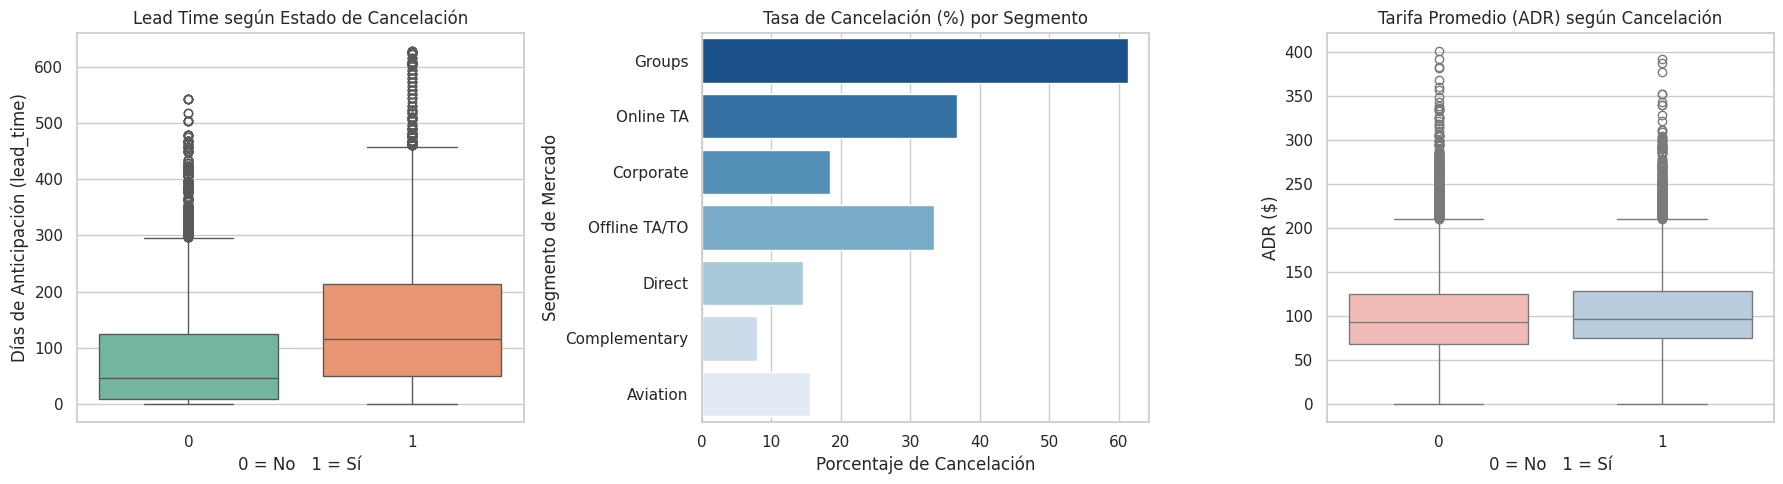

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Gráfico 1: Lead Time vs Cancelación (Boxplot o Violinplot)
sns.boxplot(data=reservas, x='is_canceled', y='lead_time', ax=axes[0], palette='Set2')
axes[0].set_title('Lead Time según Estado de Cancelación')
axes[0].set_xlabel('0 = No   1 = Sí')
axes[0].set_ylabel('Días de Anticipación (lead_time)')

# Gráfico 2: Tasa de cancelación por Segmento de Mercado
df_market = con.sql("""
SELECT market_segment, ROUND(SUM(is_canceled) * 100.0 / COUNT(*), 2) AS tasa
FROM reservas GROUP BY market_segment
""").df()
sns.barplot(data=df_market, x='tasa', y='market_segment', ax=axes[1], palette='Blues_r')
axes[1].set_title('Tasa de Cancelación (%) por Segmento')
axes[1].set_xlabel('Porcentaje de Cancelación')
axes[1].set_ylabel('Segmento de Mercado')

# Gráfico 3: ADR vs Cancelación
sns.boxplot(data=reservas, x='is_canceled', y='adr', ax=axes[2], palette='Pastel1')
axes[2].set_title('Tarifa Promedio (ADR) según Cancelación')
axes[2].set_xlabel('0 = No   1 = Sí')
axes[2].set_ylabel('ADR ($)')

plt.tight_layout()
plt.show()

- ## Interpretación:
Los gráficos de caja muestran que la mediana y el rango intercuartil del lead_time son considerablemente superiores cuando is_canceled = 1. Asimismo, los gráficos de barras evidencian que ciertos segmentos superan ampliamente el promedio general de cancelación.

Esto confirma que el factor temporal (cuándo se efectúa la reserva respecto a la llegada) es un determinante crítico del comportamiento del consumidor hotelero, muy por encima de otras variables estáticas.

## 11. Patrones y casos llamativos
- Se detectaron valores de adr iguales a cero o negativos, los cuales corresponden probablemente a cortesías, compensaciones o errores de registro, pero no deben eliminarse automáticamente en esta etapa exploratoria ya que forman parte de la variabilidad real de la operativa hotelera.

- Se observa una alta concentración de reservas en pocos segmentos de mercado, lo que genera desbalances importantes en los tamaños de los grupos analizados.

## 12. Variables candidatas para predecir cancelaciones
- lead_time: por su fuerte asociación directa con la cancelación.

- market_segment: por agrupar comportamientos de compra diferenciados.

- adr: por incidir directamente en el compromiso económico del cliente.

- hotel: permite diferenciar la dinámica entre hoteles urbanos y resorts.

## 13. Conclusiones exploratorias
El tiempo de anticipación es clave: Las reservas canceladas se realizan con un promedio de días de anticipación notablemente superior al de las reservas concretadas.

Heterogeneidad por canal: El comportamiento de cancelación no se distribuye de manera uniforme; depende fuertemente del canal o segmento de mercado por el cual ingresó la reserva.

Sensibilidad tarifaria: Las tarifas diarias promedio (adr) presentan comportamientos diferenciados, sugiriendo que las políticas de precios y cancelaciones flexibles influyen en la decisión final del huésped.


## 14. Alcances y limitaciones
Este análisis exploratorio identifica asociaciones y patrones, pero no permite afirmar una relación de causa-efecto definitiva sin aplicar modelospredictivos o multivariados posteriores.

El dataset no incluye variables contextuales externas que también podrían explicar picos de cancelación.